# 8 · Measuring the motion better

Notebook 7 split the published search's error by what each scene recorded, and found part of
it on drawn scrolls that neither stop nor change speed: the search's motion is wrong there. It
measures half a stream pixel off, and a scroll faster than its ±8 px reach it misses by ~16
px. So before anything learns, this notebook builds a search that measures better from the
same two received frames, and asks what that is worth - alone, and with notebook 6's stop
decision beside it.

**`models.PyramidSearch`**: the published search coarse to fine. Every offset within ±4 px at
a quarter of the resolution - ±16 stream pixels, at a quarter of the published search's
positions - then N-2 moved by what was found (`GridSample`) and ±1 searched at half the
resolution, then ±2 at full resolution, every 4th position. The last level ends below a
pixel: by the published search's softmax, a parabola through the cheapest offset and its
neighbours, or two lines of one slope - the shape a mean
absolute difference has near its minimum ("equiangular"). On 40 random shifts of a picture
the three measure to 0.31, 0.13 and 0.05 px (median). Nothing learns; every level is
`TileSearch`'s fixed convolutions.

| search | reach | below a pixel | levels |
| --- | --- | --- | --- |
| published | ±8 px | softmax at half resolution | one: half res, ±4 |
| ±16 px | ±16 px | softmax at half resolution | one: half res, ±8 - 289 offsets |
| sub-pixel only | ±8 px | equiangular at full resolution | half res ±4, full res ±2 |
| pyramid, softmax / parabola / equiangular | ±16 px | as named | quarter res ±4, half res ±1, full res ±2 |
| pyramid, equiangular, bicubic / whole-pixel carry | ±16 px | equiangular; N+1 read bicubically, or the carried offset rounded to whole pixels | as above |

What is carried to N+1 need not be as fine as what is measured. A first run carried every
search's half motion with bilinear `GridSample`, and the better the measurement the worse the
score: the published search's motions fall mostly on even pixels, so half of one is a whole
pixel and N is copied exactly, while a sub-pixel motion reads N between its pixels and blurs
it. So the carry is a choice of its own here: bilinear, bicubic, or rounded to whole pixels.

Steps:

1. **Data** - every search on the same frames of every validation clip.
2. **Measured against the scenes** - each search's motion beside the scroll the scene recorded.
3. **Scores** - carrying half, as published; and by what happened in the tile (notebook 7's labels).
4. **With the stop decision** - notebook 6's four-frame table fitted on each search's own history.
5. **As a graph** - exported with the client's contract, checked against torch, and its work.

Needs: `00_data_preprocess.ipynb` and the sources it read. Exports to `checkpoints/export/`
only; nothing is published.

In [1]:
"""Settings."""

import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import budget, history, models, runs, training, webexport
from helpers.history import GRID
from helpers.training import DEVICE

STILL, SHARPNESS, CAP, MIN_COUNT, DEPTH = 0.1, 10.0, 50.0, 200, 3
CACHE = training.CHECKPOINT_DIR / "pyramid"
SEED = 0
training.seed_everything(SEED)

manifest = training.load_manifest()
training.describe(manifest)
STEP = runs.received_every(manifest)
FRACTION = 1 / STEP


def pyramid(levels=((4, 4, 1), (2, 1, 2), (1, 2, 4)), subpixel="equiangular", **carry):
    return models.PyramidSearch(levels, SHARPNESS, FRACTION, STILL, subpixel, **carry).to(DEVICE).eval()


SEARCHES = {
    "published: ±8 px": models.TileSearch(4, 2, SHARPNESS, 2, FRACTION, still=STILL).to(DEVICE).eval(),
    "±16 px": models.TileSearch(8, 2, SHARPNESS, 2, FRACTION, still=STILL).to(DEVICE).eval(),
    "sub-pixel only: ±8 px, equiangular": pyramid(((2, 4, 2), (1, 2, 4))),
    "pyramid ±16 px, softmax": pyramid(subpixel="softmax"),
    "pyramid ±16 px, parabola": pyramid(subpixel="parabola"),
    "pyramid ±16 px, equiangular": pyramid(subpixel="equiangular"),
    "pyramid ±16 px, equiangular, bicubic carry": pyramid(subpixel="equiangular", interpolation="bicubic"),
    "pyramid ±16 px, equiangular, whole-pixel carry": pyramid(subpixel="equiangular", whole=True),
}
PUBLISHED = "published: ±8 px"
WHOLE = "pyramid ±16 px, equiangular, whole-pixel carry"

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)


## 1. Data

Every validation clip rebuilt once and every search run on the same frames
(`history.load_many`): x264 does not encode a clip the same way twice, and searches compared
on separate rebuilds would see different pictures. For each tile at every received frame N
from 6 on, each search's motion of the last three pairs and N+1 scored at 17 shares of its
newest motion - so carrying half, carrying none and anything a stop decision picks are
looked up, not warped again - and the tile's labels (`budget.events`, notebook 7).

In [2]:
CACHE.mkdir(parents=True, exist_ok=True)


def cached(split, searches, scored=None):
    path = CACHE / f"{split}_{'_'.join(sorted(s.split(':')[0].replace(' ', '').replace('±', 'r') for s in searches))}.pkl"
    if path.exists() and path.stat().st_mtime > (training.DATA_DIR / "manifest.json").stat().st_mtime:
        return pickle.loads(path.read_bytes())
    found = history.load_many(manifest, split, searches, DEPTH, 1, scored=scored)
    path.write_bytes(pickle.dumps(found))
    return found


started = time.time()
val = cached("val", SEARCHES)
tiles = val["tiles"]
sources = manifest["splits"]["val"]["sources"]
scale = manifest["scale"]
labels = []
for s, n, (y, x, h, w), (ix, iy) in zip(tiles["source"], tiles["frame"], tiles["box"], tiles["origin"]):
    labels.append(budget.primary(budget.events(sources[s], n, STEP, (scale * (ix + x), scale * (iy + y), scale * w, scale * h))))
labels = np.array(labels)
changed = tiles["changed"]
moving = val[PUBLISHED]["still"][:, 0] >= STILL                    # the published gate is open
for name in SEARCHES:
    # compared at the 50 dB cap. A sub-pixel fit can land on the other side of a near-tie when the
    # same tile is searched in another batch (the GPU's rounding), so a handful of tiles may differ
    gap = np.abs(np.minimum(np.where(val[name]["still"][:, 0] >= STILL, val[name]["scores"][:, len(GRID) // 2],
                                     val[name]["scores"][:, 0]), CAP) - np.minimum(val[name]["published"], CAP))
    assert (gap > 0.01).sum() <= max(3, 0.0005 * len(gap)), \
        f"{name}: the table does not hold the search's own pictures ({(gap > 0.01).sum()} tiles off, up to {gap.max():.3f} dB)"
    if (gap > 0.01).any():
        print(f"{name}: {(gap > 0.01).sum()} tile(s) of {len(gap)} off the table by up to {gap.max():.2f} dB (a near-tie)")
print(f"{len(changed)} tiles from {len(set(tiles['source']))} clips in {time.time() - started:.0f}s: "
      f"{moving.sum()} moving between N-2 and N, {changed.sum()} changed to N+1")

sub-pixel only: ±8 px, equiangular: 1 tile(s) of 17190 off the table by up to 0.10 dB (a near-tie)
pyramid ±16 px, parabola: 1 tile(s) of 17190 off the table by up to 0.10 dB (a near-tie)
pyramid ±16 px, equiangular: 1 tile(s) of 17190 off the table by up to 0.10 dB (a near-tie)
pyramid ±16 px, equiangular, bicubic carry: 1 tile(s) of 17190 off the table by up to 0.12 dB (a near-tie)
pyramid ±16 px, equiangular, whole-pixel carry: 1 tile(s) of 17190 off the table by up to 0.22 dB (a near-tie)
17190 tiles from 232 clips in 0s: 9084 moving between N-2 and N, 5579 changed to N+1


## 2. Measured against the scenes

On tiles whose only event is the background scroll, the scene says how far the content moved
from N-2 to N: the scroll's step, against its direction, at the stream's scale. Each search's
newest motion beside it - the median error by how far it moved, and the share measured within
half a pixel.

In [3]:
scrolled = np.flatnonzero(np.char.startswith(labels.astype(str), "scroll") & (labels != "scroll: starts"))
truth = np.array([-(np.array(sources[tiles["source"][i]]["scene"]["scroll"][tiles["frame"][i]], float)
                    - np.array(sources[tiles["source"][i]]["scene"]["scroll"][tiles["frame"][i] - STEP], float)) / scale
                  for i in scrolled])
speed = np.abs(truth).max(1)
BINS = ((0, 2), (2, 4), (4, 8), (8, 12), (12, 16), (16, 99))
print(f"{len(scrolled)} tiles moved by the scroll alone; median error of the measured motion (px), by how far it moved:")
print(f"{'':<38}" + "".join(f"{f'{a}-{b} px':>10}" for a, b in BINS) + f"{'all':>8}{'≤ ½ px':>9}")
print(f"{'tiles':<38}" + "".join(f"{((speed >= a) & (speed < b)).sum():10}" for a, b in BINS))
measured = {}
for name in SEARCHES:
    miss = np.linalg.norm(val[name]["motion"][scrolled, 0] - truth, axis=1)
    measured[name] = miss
    print(f"{name:<38}" + "".join(f"{np.median(miss[(speed >= a) & (speed < b)]):10.2f}" for a, b in BINS)
          + f"{np.median(miss):8.2f}{(miss <= 0.5).mean():9.0%}")

2004 tiles moved by the scroll alone; median error of the measured motion (px), by how far it moved:
                                          0-2 px    2-4 px    4-8 px   8-12 px  12-16 px  16-99 px     all   ≤ ½ px
tiles                                        403       490       616       223        90       182
published: ±8 px                            0.50      0.50      0.50      1.58     11.97     22.50    0.61      43%
±16 px                                      0.50      0.50      0.50      0.50      0.50     21.00    0.50      50%
sub-pixel only: ±8 px, equiangular          0.13      0.07      0.08      0.50     12.32     22.36    0.11      74%
pyramid ±16 px, softmax                     0.47      0.32      0.34      0.30      0.37     20.36    0.38      74%
pyramid ±16 px, parabola                    0.14      0.10      0.11      0.08      0.12     20.92    0.12      81%
pyramid ±16 px, equiangular                 0.12      0.07      0.08      0.08      0.09     20.99    0.

## 3. Scores

Each search carrying half its motion, gated as published - the graph's rule - and read from N
as the search says: bilinearly, bicubically, or by whole pixels. Three columns
as in notebook 6: the changed tiles (N+1 differs from N), all, and the **moving** ones (the
published gate is open) capped at 50 dB - the fair one for a stop. Then the moving tiles by
notebook 7's families of label, and the gain over the published search with its 95% range
over clips.

In [4]:
HALF = len(GRID) // 2
rng = np.random.default_rng(SEED)
clip_of = tiles["source"]


def pick(table, share):
    """(S,) the per-tile score of carrying `share` (S,) of a search's newest motion."""
    index = np.clip(np.rint(np.asarray(share) * (len(GRID) - 1)).astype(int), 0, len(GRID) - 1)
    return table["scores"][np.arange(len(index)), index]


def over_clips(gain, mask, draws=2000):
    """The 95% range of the mean of `gain` over `mask`, clips drawn with replacement."""
    per = [gain[mask & (clip_of == c)] for c in np.unique(clip_of[mask])]
    means = [np.concatenate([per[i] for i in rng.integers(0, len(per), len(per))]).mean() for _ in range(draws)]
    return np.percentile(means, [2.5, 97.5])


scores = {name: val[name]["published"] for name in SEARCHES}
scores["repeat"] = val[PUBLISHED]["scores"][:, 0]


def table_of(names):
    base = scores[PUBLISHED]
    print(f"{'wPSNR (dB)':<44}{'changed':>16}{'all':>16}{'moving, ≤ 50 dB':>18}{'95% over clips':>20}")
    for name in names:
        s = scores[name]
        gain = np.minimum(s, CAP) - np.minimum(base, CAP)
        low, high = over_clips(gain, moving) if name != PUBLISHED else (0, 0)
        print(f"{name:<44}{s[changed].mean():8.2f} ({s[changed].mean() - base[changed].mean():+5.2f})"
              f"{s.mean():8.2f} ({s.mean() - base.mean():+5.2f})"
              f"{np.minimum(s, CAP)[moving].mean():10.2f} ({gain[moving].mean():+5.2f})   [{low:+.2f}, {high:+.2f}]")


table_of(["repeat", *SEARCHES])

FAMILIES = {
    "whole tile moves": lambda label: label.startswith("scroll") and not label.endswith(": starts"),
    "part of the tile moves": lambda label: label.startswith(("drag", "region")) and not label.endswith(": starts"),
    "unannounced": lambda label: label == "menu opens or closes at N+1" or label.endswith(": starts"),
    "screen": lambda label: label == "screen",
    "video": lambda label: label == "video",
    "other": lambda label: True,
}
family = np.array([next(name for name, test in FAMILIES.items() if test(label)) for label in labels])
print(f"\n{'moving, ≤ 50 dB, by family':<44}" + "".join(f"{name:>24}" for name in FAMILIES))
print(f"{'tiles':<44}" + "".join(f"{(moving & (family == name)).sum():24}" for name in FAMILIES))
for name in ["repeat", *SEARCHES]:
    print(f"{name:<44}" + "".join(f"{np.minimum(scores[name], CAP)[moving & (family == f)].mean():24.2f}" for f in FAMILIES))

wPSNR (dB)                                           changed             all   moving, ≤ 50 dB      95% over clips
repeat                                         28.41 (-3.09)   61.35 (-0.56)     36.63 (-1.44)   [-2.18, -0.78]
published: ±8 px                               31.50 (+0.00)   61.91 (+0.00)     38.07 (+0.00)   [+0.00, +0.00]
±16 px                                         31.42 (-0.08)   61.85 (-0.06)     37.99 (-0.08)   [-0.20, +0.04]
sub-pixel only: ±8 px, equiangular             31.32 (-0.18)   60.63 (-1.28)     37.47 (-0.60)   [-0.81, -0.40]
pyramid ±16 px, softmax                        31.44 (-0.05)   61.76 (-0.15)     38.04 (-0.03)   [-0.18, +0.13]
pyramid ±16 px, parabola                       31.45 (-0.05)   61.33 (-0.58)     37.91 (-0.16)   [-0.34, +0.02]
pyramid ±16 px, equiangular                    31.39 (-0.11)   61.07 (-0.85)     37.64 (-0.43)   [-0.65, -0.24]
pyramid ±16 px, equiangular, bicubic carry     31.30 (-0.20)   61.01 (-0.90)     37.55 (-0.52)   [-0.

## 4. With the stop decision

A better measurement carries a fast scroll the whole way it went - right while it goes on, and
twice as wrong the frame it stops: notebook 4 found ±16 px alone no better on whole tiles for
that reason. So each search gets notebook 6's four-frame table: per bin of how far the motion
one and two pairs before went against the newest (`r`, `r before`), the share of the newest
motion that scored best on the moving train tiles, capped at 50 dB. Each search's table is
fitted on its own history. The train clips are measured once more, for the published search
and the pyramid that carries whole pixels (section 3).

In [5]:
R_EDGES = [-0.1, 0.1, 0.5, 0.8, 0.95, 1.05, 1.25, 1.6, 2.5, 5.0]
R2_EDGES = [0.1, 0.8, 1.25, 2.5]


def binned(values, edges):
    return np.where(np.isnan(values), len(edges) + 1, np.digitize(np.nan_to_num(values, nan=0.0), edges))


def keys(table):
    return binned(history.along(table, 1), R_EDGES) * 16 + binned(history.along(table, 2), R2_EDGES)


def fit(table):
    gate = table["still"][:, 0] >= STILL
    found, shares = keys(table), {}
    for key in np.unique(found[gate]):
        chosen = gate & (found == key)
        if chosen.sum() >= MIN_COUNT:
            shares[int(key)] = float(GRID[np.minimum(table["scores"][chosen], CAP).mean(0).argmax()])
    return shares


def decided(table, shares):
    gate = table["still"][:, 0] >= STILL
    return np.where(gate, [shares.get(int(k), 0.5) for k in keys(table)], 0.0)


BEST = WHOLE
started = time.time()
train = cached("train", {PUBLISHED: SEARCHES[PUBLISHED], BEST: SEARCHES[BEST]})
print(f"train: {len(train['tiles']['source'])} tiles in {time.time() - started:.0f}s")
for name in (PUBLISHED, BEST):
    shares = fit(train[name])
    scores[f"{name} + stop decision"] = pick(val[name], decided(val[name], shares))
    print(f"{name}: {len(shares)} bins; share per bin of r (r before in 0.8-1.25): "
          + ", ".join(f"{shares.get(b * 16 + 2, 0.5):.2f}" for b in range(len(R_EDGES) + 2)))
print()
table_of([PUBLISHED, f"{PUBLISHED} + stop decision", BEST, f"{BEST} + stop decision"])
print(f"\n{'moving, ≤ 50 dB, by family':<44}" + "".join(f"{name:>24}" for name in FAMILIES))
for name in (PUBLISHED, f"{PUBLISHED} + stop decision", BEST, f"{BEST} + stop decision"):
    print(f"{name:<44}" + "".join(f"{np.minimum(scores[name], CAP)[moving & (family == f)].mean():24.2f}" for f in FAMILIES))

train: 53775 tiles in 758s
published: ±8 px: 19 bins; share per bin of r (r before in 0.8-1.25): 0.50, 0.50, 0.50, 0.38, 0.44, 0.50, 0.50, 0.62, 0.50, 0.50, 0.50, 0.50
pyramid ±16 px, equiangular, whole-pixel carry: 19 bins; share per bin of r (r before in 0.8-1.25): 0.50, 0.50, 0.50, 0.31, 0.44, 0.50, 0.44, 0.56, 0.50, 0.50, 0.50, 0.50

wPSNR (dB)                                           changed             all   moving, ≤ 50 dB      95% over clips
published: ±8 px                               31.50 (+0.00)   61.91 (+0.00)     38.07 (+0.00)   [+0.00, +0.00]
published: ±8 px + stop decision               31.58 (+0.08)   61.95 (+0.04)     38.15 (+0.08)   [+0.01, +0.15]
pyramid ±16 px, equiangular, whole-pixel carry   31.45 (-0.05)   62.00 (+0.09)     37.99 (-0.08)   [-0.23, +0.07]
pyramid ±16 px, equiangular, whole-pixel carry + stop decision   31.75 (+0.25)   62.14 (+0.22)     38.21 (+0.15)   [-0.04, +0.34]

moving, ≤ 50 dB, by family                          whole tile moves  part o

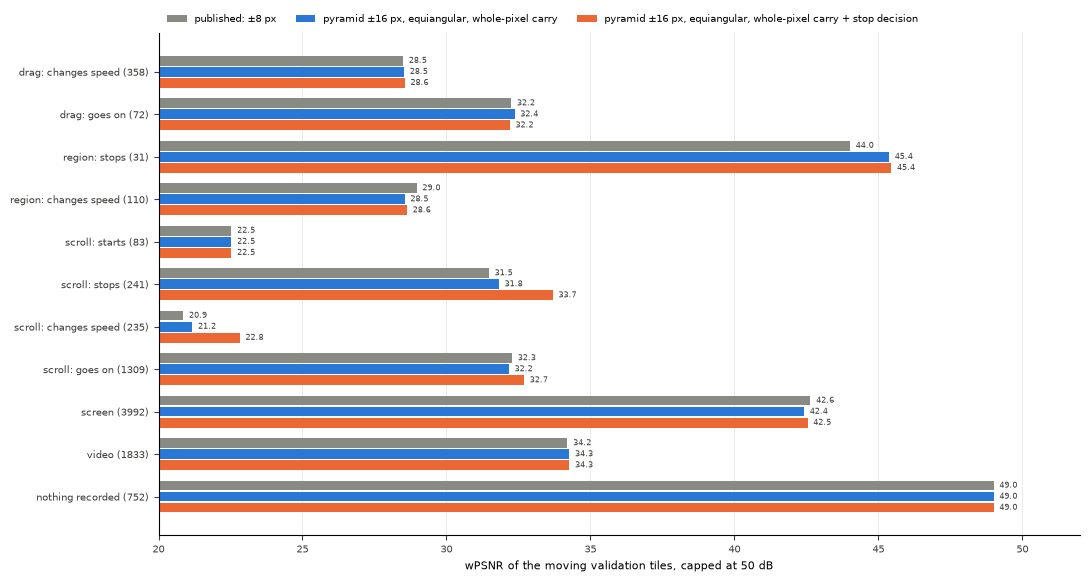

In [6]:
"""Where the gain is: per label of notebook 7, the moving tiles' mean wPSNR (capped) of the
published search, the best pyramid, and the pyramid with the stop decision."""

shown = [PUBLISHED, BEST, f"{BEST} + stop decision"]
colours = ("#8a8a85", "#2a78d6", "#eb6834")
order = [label for label in budget.LABELS if (moving & (labels == label)).sum() >= 30]
fig, ax = plt.subplots(figsize=(11, 0.42 * len(order) + 1.3))
positions = np.arange(len(order))[::-1]
height = 0.26
for k, (name, colour) in enumerate(zip(shown, colours)):
    values = [np.minimum(scores[name], CAP)[moving & (labels == label)].mean() for label in order]
    ax.barh(positions + (1 - k) * height, values, height=height - 0.03, color=colour, label=name)
    for y, value in zip(positions + (1 - k) * height, values):
        ax.text(value + 0.2, y, f"{value:.1f}", va="center", fontsize=6, color="#3d3d3a")
ax.set_yticks(positions, [f"{label} ({(moving & (labels == label)).sum()})" for label in order], fontsize=8)
ax.set_xlim(20, 52)
ax.set_xlabel("wPSNR of the moving validation tiles, capped at 50 dB", fontsize=8)
ax.legend(fontsize=7, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False)
ax.grid(axis="x", color="#e6e6e3", lw=0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(labelsize=7, colors="#3d3d3a")
fig.tight_layout()
plt.show()

## 5. As a graph

The whole-pixel pyramid carrying half its motion, as `models.Motion` exports it: the client's
contract, `previous` and `current` `[N, 3, H, W]` with `N`, `H` and `W` symbolic, into
`checkpoints/export/` (not published). Checked against torch at 36 tiles, at 4 and at one
tile smaller than the client's, and its work set beside the published graph's: the luma
positions each level samples times its offsets, and ONNX Runtime's time on this CPU for 36
tiles - a ratio, not a browser time.

In [7]:
EXPORT = training.CHECKPOINT_DIR / "export"
size = webexport.TILE_INPUT
graphs = {}
for name, filename in ((PUBLISHED, "extrapolate2x_tilesearch_r4_s2.onnx"),
                       (BEST, "extrapolate2x_pyramid_r16_equiangular.onnx")):
    model = models.Motion(search=SEARCHES[name], learned=False)
    info = webexport.export(model, filename, size, label=name, dynamic=True, models_dir=EXPORT)
    rng_check = np.random.default_rng(SEED)
    for count, shape in ((36, size), (4, size), (1, (64, 120))):
        frames = rng_check.random((count, 3, *shape)).astype(np.float32)
        moved = np.roll(frames, (3, -5), axis=(2, 3))     # something to find
        webexport.check_graph(info["path"], model, frames, moved, tolerance=5e-3)
    graphs[name] = (info, webexport.time_graph(info["path"], size, batch=36))
    print(webexport.summary_line(*graphs[name]))


def work(search):
    """Sampled luma positions times offsets, summed over the levels, for one tile."""
    height, width = size
    levels = search.levels if hasattr(search, "levels") else [(search.scale, search.radius, search.stride)]
    total = 0
    for scale, radius, stride in levels:
        positions = len(range(0, height // scale - 2 * radius, stride)) * len(range(0, width // scale - 2 * radius, stride))
        total += positions * (2 * radius + 1) ** 2
    return total


for name in SEARCHES:
    print(f"{name:<40} {work(SEARCHES[name]) / 1e6:6.2f} M differences a tile ({work(SEARCHES[name]) / work(SEARCHES[PUBLISHED]):4.2f}x published)")
print(f"\nCPU, 36 tiles: {graphs[BEST][1]:.1f} ms against the published graph's {graphs[PUBLISHED][1]:.1f} ms "
      f"({graphs[BEST][1] / graphs[PUBLISHED][1]:.2f}x)")

extrapolate2x_tilesearch_r4_s2.onnx                    35.5 KB   67.69 ms   Absx1, Addx4, Castx5, Concatx4, Constantx37, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx4, GreaterOrEqualx1, GridSamplex1, MatMulx1, Mulx8, Rangex2, Reciprocalx2, ReduceMeanx1, Reshapex3, Shapex3, Slicex1, Softmaxx1, Subx3, Unsqueezex8, Wherex1   OUTSIDE BUDGET: Abs, Cast, ConstantOfShape, Equal, Expand, Gather, GreaterOrEqual, GridSample, MatMul, Mul, Range, Reciprocal, ReduceMean, Reshape, Shape, Slice, Softmax, Sub, Unsqueeze, Where
extrapolate2x_pyramid_r16_equiangular.onnx             72.6 KB  126.35 ms   Absx5, Addx31, Andx2, ArgMinx1, Castx16, Clipx10, Concatx14, Constantx152, ConstantOfShapex5, Convx12, Divx5, Equalx3, Expandx3, Gatherx20, GatherElementsx5, Greaterx2, GreaterOrEqualx1, GridSamplex3, Lessx2, MatMulx2, Maxx2, Modx1, Mulx28, Negx4, Rangex6, Reciprocalx6, ReduceMeanx3, Reshapex9, Roundx1, Shapex11, Slicex1, Softmaxx2, Subx15, Unsqueezex34, Wherex5   OUTSIDE BUDGET: Abs, And, ArgMi

## What it says

- **The pyramid measures seven times as precisely and twice as far.** On tiles moved by a drawn
  scroll alone its motion is 0.09 px off (median), the published search's 0.61; up to 16 px
  between received frames it stays near 0.1, where the published search is 12 px off from 12 px
  on. Past 16 px every search misses. Of the sub-pixel fits the equiangular one is best (0.09
  against the parabola's 0.12 and the softmax's 0.38).
- **Reading N between its pixels costs more than the precision is worth - most of all on
  screens.** Carried bilinearly, every sub-pixel search scores under the published one on the
  moving tiles (the equiangular pyramid −0.43 dB, the sub-pixel search at ±8 px −0.60), bicubically
  no better (−0.52); on screens the equiangular pyramid loses a whole dB (41.64 against 42.64): a
  decoded text frame resampled between its pixels is blurred. Rounding what is carried to whole
  pixels takes it back (−0.08, 95% over clips −0.22 to +0.06).
- **Precision pays through the stop decision, on the drawn scrolls.** Notebook 6's table fitted on
  the pyramid's own history gains **+0.15 dB** on the moving tiles (95% over clips −0.04 to +0.34)
  and +0.25 on the changed ones - against +0.08 for the same table on the published search. On
  drawn tiles that move whole it is +0.86 (30.67 → 31.53); on screens, video and tiles that move
  in part, nothing.
- **It costs about twice the published graph.** 1.33 times the luma differences a tile, and on this
  CPU 1.87 times the time for 36 tiles (126 against 68 ms - a ratio, not a browser time). Checked
  against torch with the client's contract; not timed in a browser.
- **The stop decision is not in the graph.** It needs each tile's motions of the two pairs before -
  state the client keeps between frames and a graph input for it. The exported pyramid alone is
  −0.08 dB against the published search.

So measuring better and deciding stops is worth +0.9 dB where a drawn page or photo scrolls as
one, and nothing on the recordings, whose change is mostly not one motion of the tile.